# CodeBERT — Java Vulnerability CWE Detection

**Training data:** 90% of `vulnerability_fix_with_cwe.csv`
**Validation data:** 10% of `vulnerability_fix_with_cwe.csv`
**Test data:** `CodeLLMExp_java_only.csv` (held out, never seen during training)

**Split:** Stratified so every CWE class appears in train/validation.

> Set Runtime → T4 GPU before running.

## Step 1 — Install Dependencies

In [ ]:
import re

def clean_code(code):
    if not isinstance(code, str):
        return ''
    # Remove code block fences (```python, ```java, ```, etc.)
    code = re.sub(r'```[\w]*\n?', '', code)
    code = re.sub(r'```', '', code)
    return code.strip()

def normalize_cwe(cwe):
    if not isinstance(cwe, str) or cwe.strip() == '':
        return 'Safe'
    cwe = cwe.strip()
    if cwe.lower() in ['fixed', 'safe', 'none', 'n/a', '']:
        return 'Safe'
    # Remove leading zeros: CWE-022 -> CWE-22
    match = re.match(r'^CWE-0*(\d+)$', cwe, re.IGNORECASE)
    if match:
        return f'CWE-{match.group(1)}'
    # If it's just a number, prepend 'CWE-'
    if re.match(r'^\d+$', cwe):
        return f'CWE-{int(cwe)}'
    return cwe.upper()


In [ ]:
%%capture
!pip install transformers==4.40.0 datasets scikit-learn pandas numpy torch accelerate seaborn matplotlib tqdm

## Step 2 — Imports & GPU Setup

In [ ]:
import os, re, json, gc, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from transformers import (
    RobertaTokenizer,
    RobertaForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter
from tqdm import tqdm
from google.colab import drive

warnings.filterwarnings('ignore')
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Clear GPU memory
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    gc.collect()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    free = (torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated()) / 1024**3
    print(f'Free VRAM: {free:.2f} GB')

Device: cuda
GPU: Tesla T4
Free VRAM: 14.56 GB


## Step 3 — Configuration

In [ ]:
MODEL_NAME    = 'microsoft/codebert-base'
MAX_LEN       = 512
BATCH_SIZE    = 8
EPOCHS        = 4
LEARNING_RATE = 2e-5
WARMUP_RATIO  = 0.1
WEIGHT_DECAY  = 0.01

# ── Update this to your notebook folder in Drive ─────────────
NOTEBOOK_DIR = '/content/drive/MyDrive/Research/Experiment - 8'

TRAIN_CSV          = os.path.join(NOTEBOOK_DIR, 'vulnerability_fix_with_cwe.csv')
TEST_CSV           = os.path.join(NOTEBOOK_DIR, 'CodeLLMExp.csv')
MODEL_SAVE_PATH    = os.path.join(NOTEBOOK_DIR, 'codebert_cwe_model')
LABEL_ENCODER_PATH = os.path.join(NOTEBOOK_DIR, 'label_encoder.json')
CHECKPOINT_FILE    = os.path.join(NOTEBOOK_DIR, 'last_checkpoint.pt')

print('Config ready')

Config ready


## Step 4 — Mount Google Drive

In [ ]:
drive.mount('/content/drive')

assert os.path.exists(TRAIN_CSV), f'Training file not found: {TRAIN_CSV}'
assert os.path.exists(TEST_CSV),  f'Test file not found: {TEST_CSV}'

print(f'Train CSV : {TRAIN_CSV}  ✅')
print(f'Test CSV  : {TEST_CSV}   ✅')

Mounted at /content/drive
Train CSV : /content/drive/MyDrive/Research/Experiment - 8/vulnerability_fix_with_cwe.csv  ✅
Test CSV  : /content/drive/MyDrive/Research/Experiment - 8/CodeLLMExp.csv   ✅


## Step 5 — Load CSVs & Build Train/Test Split

**Strategy:**
- Load `vulnerability_fix_with_cwe.csv`.
- Split `vulnerability_fix_with_cwe.csv` into 90% for training and 10% for validation, stratified by CWE.
- Load `CodeLLMExp_java_only.csv` entirely as the dedicated test set.
- Stratified splits ensure all CWE classes appear appropriately in train/validation.

In [ ]:
# ── Load primary source CSV (vulnerability_fix_with_cwe.csv) ────────────────────────────────
# Columns: vulnerability_type, vulnerable_code, fixed_code, CWE
df_primary_source = pd.read_csv(TRAIN_CSV)
df_primary_source = df_primary_source[['vulnerable_code', 'CWE']].copy()
df_primary_source.columns = ['code_raw', 'cwe_raw']
df_primary_source['code_clean'] = df_primary_source['code_raw'].apply(clean_code)
df_primary_source['cwe_norm']   = df_primary_source['cwe_raw'].apply(normalize_cwe)
df_primary_source = df_primary_source[df_primary_source['code_clean'].str.len() > 20].reset_index(drop=True)

print(f'Primary source samples (from {os.path.basename(TRAIN_CSV)}): {len(df_primary_source):,}')
print(f'Primary source CWE classes                        : {df_primary_source["cwe_norm"].nunique()}')

# ── Load dedicated test CSV (CodeLLMExp_java_only.csv) ─────────────────────────────────────────────
# Columns: language, cwe, severity, rate, code, label, ...
df_test = pd.read_csv(TEST_CSV)
df_test = df_test[['code', 'cwe']].copy()
df_test.columns = ['code_raw', 'cwe_raw']
df_test['code_clean'] = df_test['code_raw'].apply(clean_code)
df_test['cwe_norm']   = df_test['cwe_raw'].apply(normalize_cwe)
df_test = df_test[df_test['code_clean'].str.len() > 10].reset_index(drop=True)

print(f'\nDedicated test samples (from {os.path.basename(TEST_CSV)})    : {len(df_test):,}')
print(f'Dedicated test CWE classes                          : {df_test["cwe_norm"].nunique()}')
print(f'\nDedicated test CWE distribution:')
print(df_test['cwe_norm'].value_counts())

Primary source samples (from vulnerability_fix_with_cwe.csv): 31,843
Primary source CWE classes                        : 5

Dedicated test samples (from CodeLLMExp.csv)    : 285
Dedicated test CWE classes                          : 5

Dedicated test CWE distribution:
cwe_norm
CWE-22     107
CWE-77      80
CWE-502     39
CWE-79      32
CWE-89      27
Name: count, dtype: int64


In [ ]:
# ── Stratified 90/10 split of df_primary_source for training and validation ───────────────────────
# Handle rare classes in df_primary_source (need at least 2 samples for 90/10 split)
cwe_counts_primary = df_primary_source['cwe_norm'].value_counts()
rare_cwes_primary  = set(cwe_counts_primary[cwe_counts_primary < 2].index)
normal_cwes_primary = set(cwe_counts_primary[cwe_counts_primary >= 2].index)

df_primary_rare   = df_primary_source[df_primary_source['cwe_norm'].isin(rare_cwes_primary)]
df_primary_normal = df_primary_source[df_primary_source['cwe_norm'].isin(normal_cwes_primary)]

if rare_cwes_primary:
    print(f'Rare CWEs in primary source (all go to training): {sorted(rare_cwes_primary)}')

# Stratified split on normal CWEs
df_train, df_val = train_test_split(
    df_primary_normal,
    test_size    = 0.1, # 10% for validation
    random_state = SEED,
    stratify     = df_primary_normal['cwe_norm']
)

# Add rare CWEs entirely to training
df_train = pd.concat([df_train, df_primary_rare], ignore_index=True)

print(f'\nTraining set (90% of primary source): {len(df_train):,} samples')
print(f'Validation set (10% of primary source): {len(df_val):,} samples')
print(f'Dedicated Test set (100% of {os.path.basename(TEST_CSV)}): {len(df_test):,} samples') # df_test is already loaded

print(f'\nTraining set CWE distribution:')
print(df_train['cwe_norm'].value_counts())
print(f'\nValidation set CWE distribution:')
print(df_val['cwe_norm'].value_counts())


Training set (90% of primary source): 28,658 samples
Validation set (10% of primary source): 3,185 samples
Dedicated Test set (100% of CodeLLMExp.csv): 285 samples

Training set CWE distribution:
cwe_norm
CWE-79     8439
CWE-89     6567
CWE-77     6252
CWE-22     5850
CWE-502    1550
Name: count, dtype: int64

Validation set CWE distribution:
cwe_norm
CWE-79     938
CWE-89     730
CWE-77     695
CWE-22     650
CWE-502    172
Name: count, dtype: int64


In [ ]:
# ── Summary of final dataset splits ─────────────────────────
print(f'Final Training Samples   : {len(df_train):,}')
print(f'Final Validation Samples : {len(df_val):,}')
print(f'Final Test Samples       : {len(df_test):,}')

print(f'\nTraining CWE distribution:')
print(df_train['cwe_norm'].value_counts())
print(f'\nValidation CWE distribution:')
print(df_val['cwe_norm'].value_counts())
print(f'\nTest CWE distribution (from {os.path.basename(TEST_CSV)}):')
print(df_test['cwe_norm'].value_counts())

Final Training Samples   : 28,658
Final Validation Samples : 3,185
Final Test Samples       : 285

Training CWE distribution:
cwe_norm
CWE-79     8439
CWE-89     6567
CWE-77     6252
CWE-22     5850
CWE-502    1550
Name: count, dtype: int64

Validation CWE distribution:
cwe_norm
CWE-79     938
CWE-89     730
CWE-77     695
CWE-22     650
CWE-502    172
Name: count, dtype: int64

Test CWE distribution (from CodeLLMExp.csv):
cwe_norm
CWE-22     107
CWE-77      80
CWE-502     39
CWE-79      32
CWE-89      27
Name: count, dtype: int64


## Step 6 — Label Encoding

In [ ]:
# Build label set from ALL unique CWEs across both train and test
all_classes = sorted(set(df_train['cwe_norm'].unique()) | set(df_test['cwe_norm'].unique()))

le = LabelEncoder()
le.fit(all_classes)

df_train['label_enc'] = le.transform(df_train['cwe_norm'])
df_test['label_enc']  = le.transform(df_test['cwe_norm'])

NUM_CLASSES = len(le.classes_)
print(f'Total classes : {NUM_CLASSES}')
print(f'Classes       : {list(le.classes_)}')

label_map = {int(i): str(c) for i, c in enumerate(le.classes_)}
with open(LABEL_ENCODER_PATH, 'w') as f:
    json.dump(label_map, f, indent=2)
print(f'Label encoder saved')

Total classes : 5
Classes       : [np.str_('CWE-22'), np.str_('CWE-502'), np.str_('CWE-77'), np.str_('CWE-79'), np.str_('CWE-89')]
Label encoder saved


## Step 7 — Tokenizer

In [ ]:
print(f'Loading tokenizer: {MODEL_NAME}')
tokenizer = RobertaTokenizer.from_pretrained(MODEL_NAME)
print('Tokenizer loaded')

Loading tokenizer: microsoft/codebert-base
Tokenizer loaded


## Step 8 — Dataset Class

In [ ]:
class JavaCWEDataset(Dataset):
    def __init__(self, codes, labels, tokenizer, max_len):
        self.codes     = codes
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.codes)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            str(self.codes[idx]),
            max_length     = self.max_len,
            padding        = 'max_length',
            truncation     = True,
            return_tensors = 'pt'
        )
        return {
            'input_ids'      : encoding['input_ids'].squeeze(0),
            'attention_mask' : encoding['attention_mask'].squeeze(0),
            'label'          : torch.tensor(int(self.labels[idx]), dtype=torch.long)
        }

print('Dataset class defined')

Dataset class defined


## Step 9 — Train/Validation Split & DataLoaders

In [ ]:
df_val['label_enc'] = le.transform(df_val['cwe_norm'])

# The df_train, df_val, and df_test DataFrames are already prepared.
# No further splitting needed here for train/val.

# Remove classes with fewer than 1 sample (should be none after stratified split, but for safety)
labels_list_train = df_train['label_enc'].tolist()
label_counts_train = Counter(labels_list_train)
rare_classes_train = {cls for cls, cnt in label_counts_train.items() if cnt < 1}
if rare_classes_train:
    rare_names_train = le.inverse_transform(sorted(rare_classes_train))
    print(f'Removing {len(rare_classes_train)} rare class(es) from training: {list(rare_names_train)}')
    keep_train        = [l not in rare_classes_train for l in labels_list_train]
    df_train          = df_train[keep_train].reset_index(drop=True)

labels_list_val = df_val['label_enc'].tolist()
label_counts_val = Counter(labels_list_val)
rare_classes_val = {cls for cls, cnt in label_counts_val.items() if cnt < 1}
if rare_classes_val:
    rare_names_val = le.inverse_transform(sorted(rare_classes_val))
    print(f'Removing {len(rare_classes_val)} rare class(es) from validation: {list(rare_names_val)}')
    keep_val        = [l not in rare_classes_val for l in labels_list_val]
    df_val          = df_val[keep_val].reset_index(drop=True)

train_dataset = JavaCWEDataset(
    df_train['code_clean'].tolist(),
    df_train['label_enc'].tolist(),
    tokenizer, MAX_LEN
)
val_dataset   = JavaCWEDataset(
    df_val['code_clean'].tolist(),
    df_val['label_enc'].tolist(),
    tokenizer, MAX_LEN
)
test_dataset  = JavaCWEDataset(
    df_test['code_clean'].tolist(),
    df_test['label_enc'].tolist(),
    tokenizer, MAX_LEN
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Train  : {len(train_dataset):,} samples  ({len(train_loader):,} batches)')
print(f'Val    : {len(val_dataset):,} samples  ({len(val_loader):,} batches)')
print(f'Test   : {len(test_dataset):,} samples  ({len(test_loader):,} batches)')

Train  : 28,658 samples  (3,583 batches)
Val    : 3,185 samples  (399 batches)
Test   : 285 samples  (36 batches)


## Step 10 — Load CodeBERT Model

In [ ]:
torch.cuda.empty_cache()
gc.collect()

print(f'Loading {MODEL_NAME} with {NUM_CLASSES} output classes...')
model = RobertaForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels = NUM_CLASSES
).to(DEVICE)

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params    : {total:,}')
print(f'Trainable params: {trainable:,}')

Loading microsoft/codebert-base with 5 output classes...


pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at microsoft/codebert-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Total params    : 124,649,477
Trainable params: 124,649,477


## Step 11 — Training Setup & Checkpoint Resume

In [ ]:
# Class weights for imbalanced CWEs
labels_list = labels_list_train + labels_list_val # Corrected: Define labels_list
actual_labels = sorted(set(labels_list))
class_weights = compute_class_weight(
    class_weight = 'balanced',
    classes      = np.array(actual_labels),
    y            = labels_list
)
full_weights = np.ones(NUM_CLASSES)
for i, cls in enumerate(actual_labels):
    full_weights[cls] = class_weights[i]

loss_fn = nn.CrossEntropyLoss(
    weight=torch.tensor(full_weights, dtype=torch.float).to(DEVICE)
)

os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

# ── Resume from checkpoint if exists ─────────────────────────
start_epoch  = 1
best_val_acc = 0.0
history      = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

if os.path.exists(CHECKPOINT_FILE):
    print('Checkpoint found — resuming...')
    torch.cuda.empty_cache()
    gc.collect()

    # Load to CPU first to avoid OOM
    ckpt = torch.load(CHECKPOINT_FILE, map_location='cpu')

    # Extract everything before deleting
    saved_epoch  = ckpt['epoch']
    best_val_acc = ckpt['best_val_acc']
    history      = ckpt['history']
    model_state  = ckpt['model_state']
    del ckpt
    torch.cuda.empty_cache()
    gc.collect()

    # Load weights: CPU → load → GPU
    model.cpu()
    model.load_state_dict(model_state)
    del model_state
    torch.cuda.empty_cache()
    gc.collect()
    model.to(DEVICE)

    start_epoch = saved_epoch + 1
    print(f'  Resumed from epoch : {saved_epoch}')
    print(f'  Best val acc so far: {best_val_acc:.4f}')
    print(f'  Next epoch         : {start_epoch}')
else:
    print('No checkpoint found — starting from scratch')

# Always build optimizer and scheduler fresh (never load from checkpoint)
total_steps  = len(train_loader) * (EPOCHS - start_epoch + 1)
warmup_steps = int(total_steps * WARMUP_RATIO)

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps   = warmup_steps,
    num_training_steps = total_steps
)

print(f'\nRemaining steps : {total_steps:,}')
print(f'Warmup steps    : {warmup_steps:,}')
print(f'Starting epoch  : {start_epoch}')

Checkpoint found — resuming...
  Resumed from epoch : 2
  Best val acc so far: 0.9516
  Next epoch         : 3

Remaining steps : 7,166
Warmup steps    : 716
Starting epoch  : 3


## Step 12 — Training & Evaluation Functions

In [ ]:
def train_epoch(model, loader, optimizer, scheduler, loss_fn, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    bar = tqdm(loader, desc='  Training', unit='batch')

    for batch in bar:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['label'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss    = loss_fn(outputs.logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()

        if (bar.n + 1) % 100 == 0:
            torch.cuda.empty_cache()

        total_loss += loss.item()
        preds       = torch.argmax(outputs.logits, dim=1)
        correct    += (preds == labels).sum().item()
        total      += labels.size(0)
        bar.set_postfix(loss=f'{total_loss/(bar.n+1):.4f}', acc=f'{correct/total:.4f}')

    return total_loss / len(loader), correct / total


def evaluate(model, loader, loss_fn, device, desc='Evaluating'):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []
    bar = tqdm(loader, desc=f'  {desc}', unit='batch')

    with torch.no_grad():
        for batch in bar:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['label'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            loss    = loss_fn(outputs.logits, labels)

            total_loss += loss.item()
            preds       = torch.argmax(outputs.logits, dim=1)
            correct    += (preds == labels).sum().item()
            total      += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            bar.set_postfix(loss=f'{total_loss/(bar.n+1):.4f}', acc=f'{correct/total:.4f}')

    return total_loss / len(loader), correct / total, all_preds, all_labels

print('Functions defined')

Functions defined


## Step 13 — Fine-Tuning Loop

In [ ]:
print('=' * 55)
print(f'  Fine-Tuning CodeBERT — {EPOCHS} Epochs')
print('=' * 55)

for epoch in range(start_epoch, EPOCHS + 1):
    print(f'\nEpoch {epoch}/{EPOCHS}')
    print('-' * 40)

    train_loss, train_acc = train_epoch(
        model, train_loader, optimizer, scheduler, loss_fn, DEVICE
    )
    val_loss, val_acc, _, _ = evaluate(
        model, val_loader, loss_fn, DEVICE, desc='Validating'
    )

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f'  Train — Loss: {train_loss:.4f} | Acc: {train_acc:.4f}')
    print(f'  Val   — Loss: {val_loss:.4f} | Acc: {val_acc:.4f}')

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        model.save_pretrained(MODEL_SAVE_PATH)
        tokenizer.save_pretrained(MODEL_SAVE_PATH)
        print(f'  Best model saved (val_acc={best_val_acc:.4f})')

    # Save checkpoint after every epoch
    torch.save({
        'epoch'       : epoch,
        'model_state' : model.state_dict(),
        'best_val_acc': best_val_acc,
        'history'     : history
    }, CHECKPOINT_FILE)
    print(f'  Checkpoint saved → epoch {epoch}')

print(f'\nTraining complete. Best Val Accuracy: {best_val_acc:.4f}')

  Fine-Tuning CodeBERT — 4 Epochs

Epoch 3/4
----------------------------------------


  Validating: 100%|██████████| 399/399 [02:03<00:00,  3.24batch/s, acc=0.9516, loss=0.1260]


  Train — Loss: 0.1364 | Acc: 0.9500
  Val   — Loss: 0.1260 | Acc: 0.9516
  Checkpoint saved → epoch 3

Epoch 4/4
----------------------------------------


  Validating: 100%|██████████| 399/399 [02:02<00:00,  3.25batch/s, acc=0.9516, loss=0.1290]


  Train — Loss: 0.1303 | Acc: 0.9500
  Val   — Loss: 0.1290 | Acc: 0.9516
  Checkpoint saved → epoch 4

Training complete. Best Val Accuracy: 0.9516


## Step 14 — Training Curves

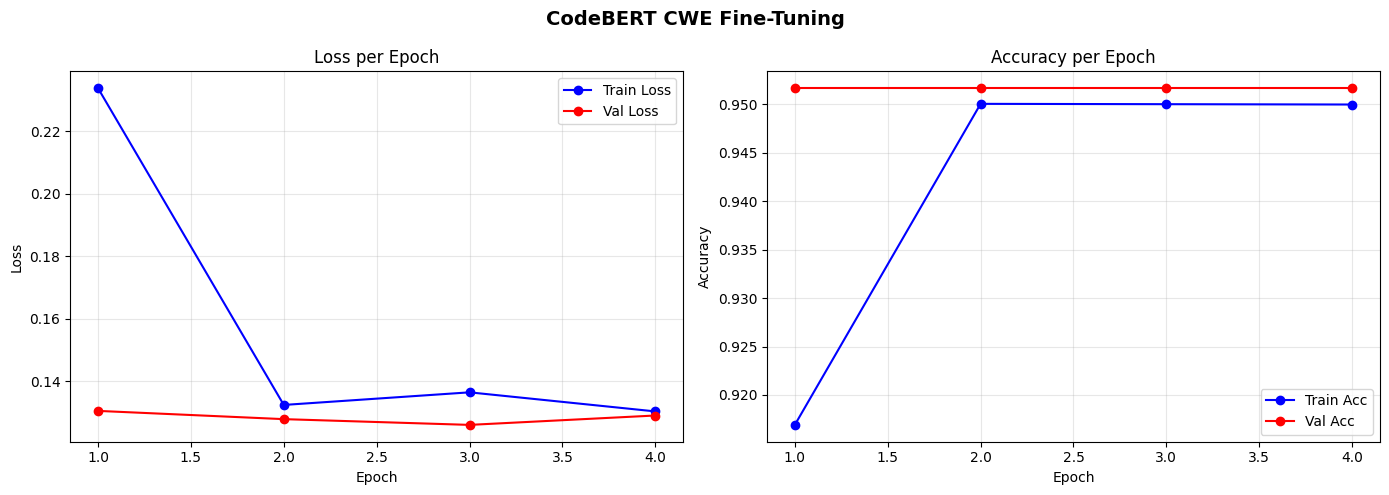

Saved: training_curves.png


In [ ]:
epochs_range = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history['train_loss'], 'b-o', label='Train Loss')
axes[0].plot(epochs_range, history['val_loss'],   'r-o', label='Val Loss')
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history['train_acc'], 'b-o', label='Train Acc')
axes[1].plot(epochs_range, history['val_acc'],   'r-o', label='Val Acc')
axes[1].set_title('Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('CodeBERT CWE Fine-Tuning', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: training_curves.png')

## Step 15 — Test

In [ ]:
print('Loading best saved model...')
torch.cuda.empty_cache()
gc.collect()

best_model = RobertaForSequenceClassification.from_pretrained(
    MODEL_SAVE_PATH,
    num_labels = NUM_CLASSES
).to(DEVICE)

print('Running inference on test set.')
test_loss, test_acc, test_preds_enc, test_labels_enc = evaluate(
    best_model, test_loader, loss_fn, DEVICE, desc='Testing'
)

test_preds_cwe  = le.inverse_transform(test_preds_enc)
test_actual_cwe = le.inverse_transform(test_labels_enc)

print(f'\nTest Loss     : {test_loss:.4f}')
print(f'Test Accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)')

Loading best saved model...
Running inference on test set.


  Testing: 100%|██████████| 36/36 [00:10<00:00,  3.32batch/s, acc=0.5579, loss=3.8221]


Test Loss     : 3.8221
Test Accuracy : 0.5579  (55.79%)


## Step 16 — Accuracy Report

In [ ]:
overall_acc = accuracy_score(test_actual_cwe, test_preds_cwe)
macro_f1    = f1_score(test_actual_cwe, test_preds_cwe, average='macro',    zero_division=0)
weighted_f1 = f1_score(test_actual_cwe, test_preds_cwe, average='weighted', zero_division=0)

print('=' * 55)
print('           TEST RESULTS SUMMARY')
print('=' * 55)
print(f'  Overall Accuracy  : {overall_acc*100:.2f}%')
print(f'  Macro F1          : {macro_f1:.4f}')
print(f'  Weighted F1       : {weighted_f1:.4f}')
print(f'  Test samples      : {len(test_preds_cwe):,}')
print('=' * 55)
print('\nPer-Class Report:')
print(classification_report(test_actual_cwe, test_preds_cwe, zero_division=0))

           TEST RESULTS SUMMARY
  Overall Accuracy  : 55.79%
  Macro F1          : 0.4709
  Weighted F1       : 0.5071
  Test samples      : 285

Per-Class Report:
              precision    recall  f1-score   support

      CWE-22       1.00      0.91      0.95       107
     CWE-502       1.00      0.03      0.05        39
      CWE-77       1.00      0.03      0.05        80
      CWE-79       0.21      1.00      0.34        32
      CWE-89       0.93      1.00      0.96        27

    accuracy                           0.56       285
   macro avg       0.83      0.59      0.47       285
weighted avg       0.90      0.56      0.51       285



## Step 17 — Confusion Matrix

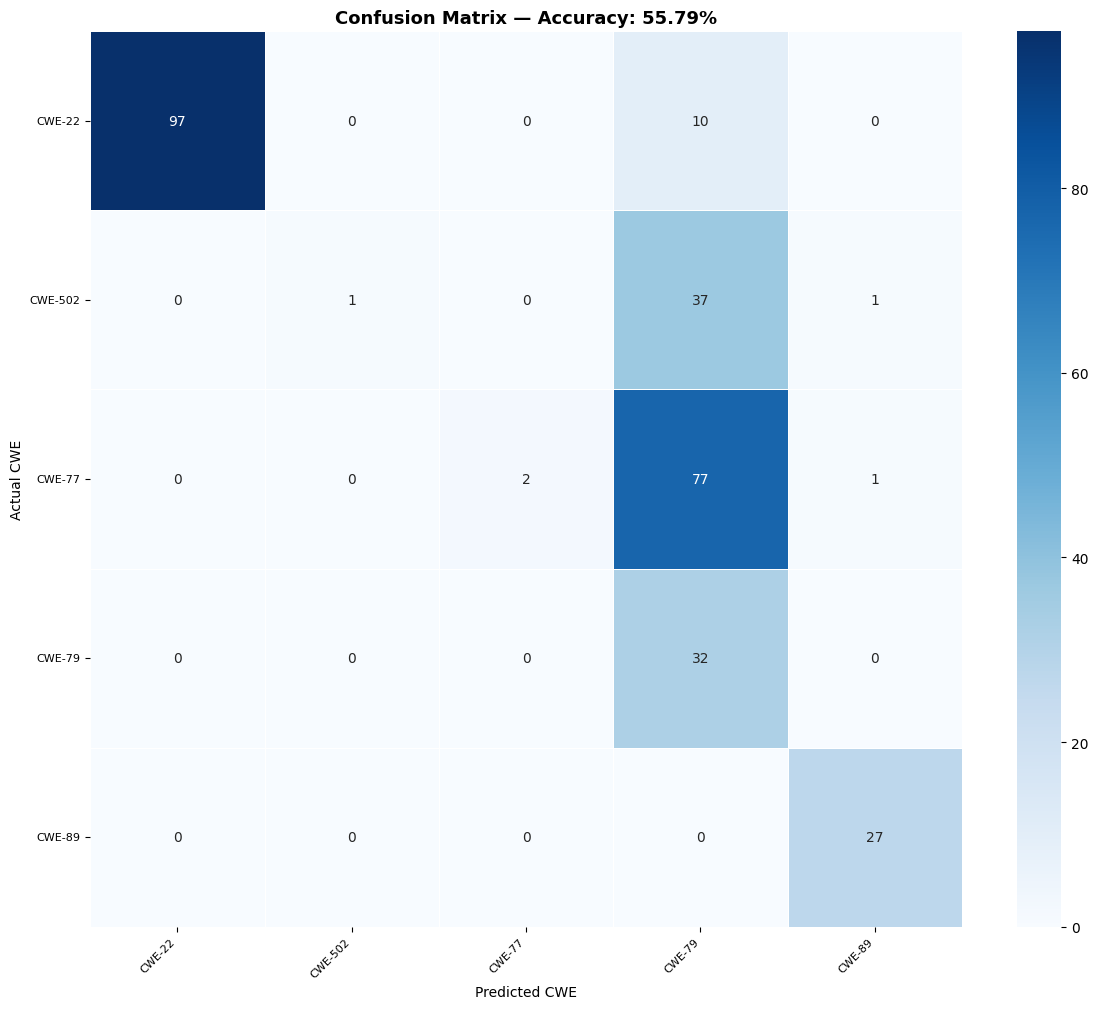

Saved: confusion_matrix.png


In [ ]:
unique_labels = sorted(set(test_actual_cwe.tolist() + test_preds_cwe.tolist()))
cm = confusion_matrix(test_actual_cwe, test_preds_cwe, labels=unique_labels)

fig_size = max(12, len(unique_labels) * 0.6)
plt.figure(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=unique_labels, yticklabels=unique_labels, linewidths=0.5)
plt.title(f'Confusion Matrix — Accuracy: {overall_acc*100:.2f}%', fontsize=13, fontweight='bold')
plt.xlabel('Predicted CWE')
plt.ylabel('Actual CWE')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion_matrix.png')

## Step 18 — Per-CWE Accuracy Chart

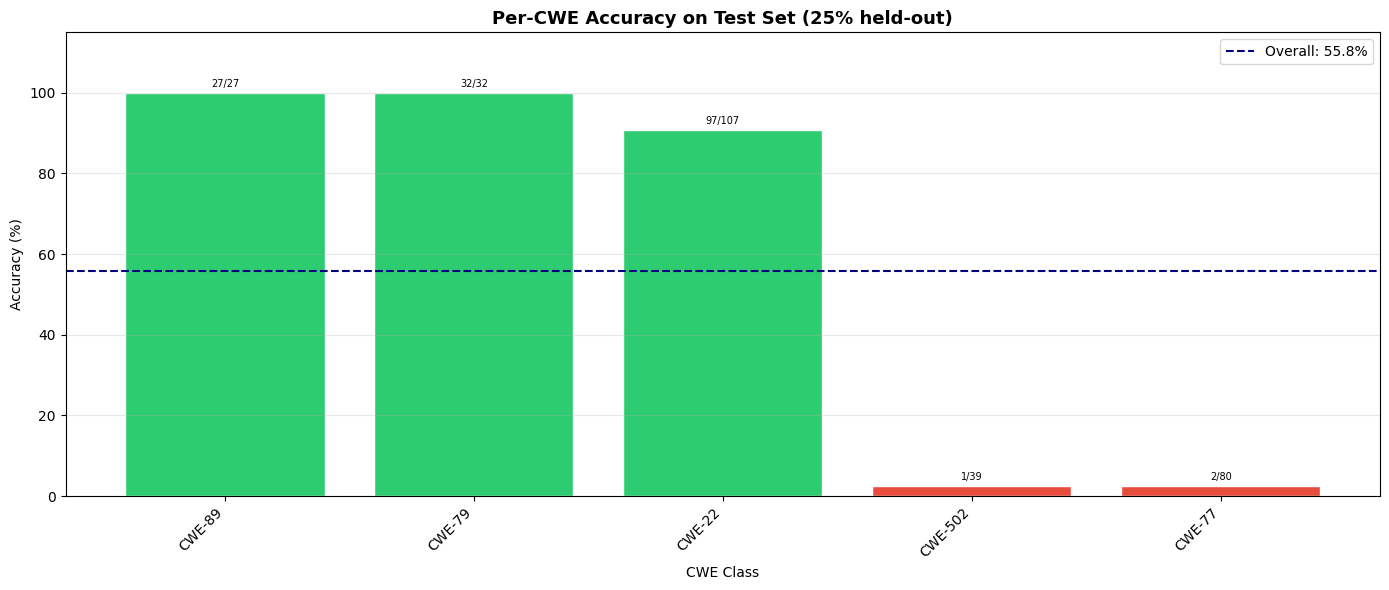

Saved: per_cwe_accuracy.png


In [ ]:
results_df = pd.DataFrame({'actual': test_actual_cwe, 'predicted': test_preds_cwe})
results_df['correct'] = results_df['actual'] == results_df['predicted']

per_cwe = results_df.groupby('actual')['correct'].agg(['sum','count'])
per_cwe['accuracy'] = per_cwe['sum'] / per_cwe['count']
per_cwe = per_cwe.sort_values('accuracy', ascending=False)

colors = ['#2ecc71' if a >= 0.7 else '#e67e22' if a >= 0.4 else '#e74c3c' for a in per_cwe['accuracy']]

plt.figure(figsize=(14, 6))
bars = plt.bar(per_cwe.index, per_cwe['accuracy'] * 100, color=colors, edgecolor='white')
for bar, (_, row) in zip(bars, per_cwe.iterrows()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f"{int(row['sum'])}/{int(row['count'])}", ha='center', va='bottom', fontsize=7)

plt.axhline(y=overall_acc*100, color='navy', linestyle='--', label=f'Overall: {overall_acc*100:.1f}%')
plt.title('Per-CWE Accuracy on Test Set (25% held-out)', fontsize=13, fontweight='bold')
plt.xlabel('CWE Class')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 115)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(NOTEBOOK_DIR, 'per_cwe_accuracy.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: per_cwe_accuracy.png')

## Step 19 — Export Results CSV

In [ ]:
output_df = pd.DataFrame({
    'code'          : df_test['code_clean'].values,
    'actual_cwe'    : test_actual_cwe,
    'predicted_cwe' : test_preds_cwe,
    'correct'       : (test_actual_cwe == test_preds_cwe)
})

RESULTS_PATH = os.path.join(NOTEBOOK_DIR, 'cwe_prediction_results.csv')
output_df.to_csv(RESULTS_PATH, index=False)

print(f'Results saved to Drive: {RESULTS_PATH}')
print(f'Total   : {len(output_df):,}')
print(f'Correct : {output_df["correct"].sum():,}')
print(f'Wrong   : {(~output_df["correct"]).sum():,}')
print(f'Accuracy: {output_df["correct"].mean()*100:.2f}%')

## Step 20 — Predict a Single Code Snippet

In [ ]:
def predict_cwe(java_code, model, tokenizer, label_encoder, device, max_len=512):
    code = clean_code(java_code)
    enc  = tokenizer(code, max_length=max_len, padding='max_length',
                     truncation=True, return_tensors='pt')
    model.eval()
    with torch.no_grad():
        out   = model(input_ids=enc['input_ids'].to(device),
                      attention_mask=enc['attention_mask'].to(device))
        probs = torch.softmax(out.logits, dim=1).squeeze(0)
        idx   = torch.argmax(probs).item()
        cwe   = label_encoder.inverse_transform([idx])[0]
        conf  = probs[idx].item()
    top3 = [(label_encoder.inverse_transform([i])[0], probs[i].item())
            for i in torch.topk(probs, min(3, len(probs))).indices.tolist()]
    return cwe, conf, top3


sample = """
import java.sql.*;
public class LoginService {
    public ResultSet login(String user, String pass) throws Exception {
        Statement st = conn.createStatement();
        return st.executeQuery(
            "SELECT * FROM users WHERE name='" + user + "' AND pass='" + pass + "'"
        );
    }
}
"""

cwe, conf, top3 = predict_cwe(sample, best_model, tokenizer, le, DEVICE)

print('=' * 45)
print(f'  Predicted CWE : {cwe}')
print(f'  Confidence    : {conf*100:.2f}%')
print('  Top 3:')
for c, p in top3:
    print(f'    {c:15s} -> {p*100:.2f}%')
print('=' * 45)

  Predicted CWE : CWE-89
  Confidence    : 99.99%
  Top 3:
    CWE-89          -> 99.99%
    CWE-434         -> 0.00%
    CWE-200         -> 0.00%


In [ ]:
# ── Stage 1: Binary Vulnerability Detector ──────────────────────────────────
# Proposal §4.2: Fine-tune CodeBERT as a binary classifier (vulnerable vs non-vulnerable)
# Non-vulnerable samples terminate here; only vulnerable ones proceed to Stage 2 (CWE classification)

BINARY_MODEL_SAVE_PATH = os.path.join(NOTEBOOK_DIR, 'codebert_binary_model')
BINARY_CHECKPOINT_FILE = os.path.join(NOTEBOOK_DIR, 'binary_checkpoint.pt')
BINARY_EPOCHS = 4
# FNR-focused threshold: lower threshold catches more real vulnerabilities
# (missing a real vulnerability costs more than a false alarm — proposal §4.2)
BINARY_THRESHOLD = 0.3

# Build binary labels:
# 'Safe' CWE → 0 (non-vulnerable), anything else → 1 (vulnerable)
df_train['binary_label'] = (df_train['cwe_norm'] != 'Safe').astype(int)
df_val['binary_label']   = (df_val['cwe_norm']   != 'Safe').astype(int)
df_test['binary_label']  = (df_test['cwe_norm']  != 'Safe').astype(int)

print("Binary label distribution — Train:")
print(df_train['binary_label'].value_counts())
print("\nBinary label distribution — Val:")
print(df_val['binary_label'].value_counts())
print("\nBinary label distribution — Test:")
print(df_test['binary_label'].value_counts())